# 3. Final Model — Selected Method Only
**Day-ahead Electricity Demand Forecasting**

Notebook 2-il ethu model best aayath ennu kandu. Ee notebook-il ath model **onnu mathram** train cheythu, final evaluation + predictions + plots undakkunnu.

Ee notebook run cheyyunnathinu munpe **Notebook 1 and 2 run cheythirikkanam** — avide undakkiya `processed_data.csv` and `selected_model.json` ivide use cheyyunnu.

## 3.1 Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 3.2 Load the selection made in Notebook 2

In [3]:
with open('../outputs/selected_model.json') as f:
    selection = json.load(f)

best_model_name = selection['best_model_name']
feature_cols = selection['feature_cols']
target_col = selection['target_col']

print('Selected model:', best_model_name)
print('Features:', feature_cols)
print('Previous test metrics:', selection['test_metrics'])

Selected model: RandomForest
Features: ['Hour_sin', 'Hour_cos', 'Month_sin', 'Month_cos', 'DoW_sin', 'DoW_cos', 'Is_Weekend', 'Quarter', 'Year', 'Wind_Capacity', 'Solar_Capacity', 'Demand_Previous_24hr', 'Demand_Previous_7days']
Previous test metrics: {'MAE': 1334.7257133212336, 'RMSE': 1816.955408597474, 'MAPE': 4.9998369607456254, 'Accuracy_%': 95.00016303925437}


## 3.3 Load cleaned data

In [4]:
df = pd.read_csv('England_Wales_Electricity_2021_2025_for_prediction.csv', parse_dates=['Date', 'Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)
df = df.dropna(subset=feature_cols + [target_col]).reset_index(drop=True)
print('Shape:', df.shape)

Shape: (86976, 27)


## 3.4 Time-based train/test split (same as Notebook 2)

In [5]:
split_date = df['Datetime'].max() - pd.Timedelta(days=90)
train = df[df['Datetime'] <= split_date]
test = df[df['Datetime'] > split_date]

X_train, y_train = train[feature_cols], train[target_col]
X_test, y_test = test[feature_cols], test[target_col]

print(f'Train: {len(train)} rows | Test: {len(test)} rows')

Train: 82654 rows | Test: 4322 rows


## 3.5 Build the selected model

Notebook 2-il select cheytha model peru vachu, correct model class automatic-ayi choose cheyyunnu (manually edit cheyyendathilla).

In [6]:
MODEL_REGISTRY = {
    'LinearRegression': lambda: LinearRegression(),
    'RandomForest': lambda: RandomForestRegressor(
        n_estimators=300, max_depth=14, n_jobs=-1, random_state=42
    ),
    'GradientBoosting': lambda: HistGradientBoostingRegressor(
        max_iter=400, max_depth=6, learning_rate=0.05, random_state=42
    ),
}

model = MODEL_REGISTRY[best_model_name]()
print('Training:', best_model_name)
model.fit(X_train, y_train)

Training: RandomForest


,n_estimators,300
,criterion,'squared_error'
,max_depth,14
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 3.6 Evaluate on test set

In [7]:
pred = model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = mean_absolute_percentage_error(y_test, pred) * 100
accuracy = 100 - mape

print(f'MAE:      {mae:.2f} MW')
print(f'RMSE:     {rmse:.2f} MW')
print(f'MAPE:     {mape:.2f}%')
print(f'Accuracy: {accuracy:.2f}%')

MAE:      1334.73 MW
RMSE:     1816.96 MW
MAPE:     5.00%
Accuracy: 95.00%


## 3.7 Plot: Actual vs Predicted

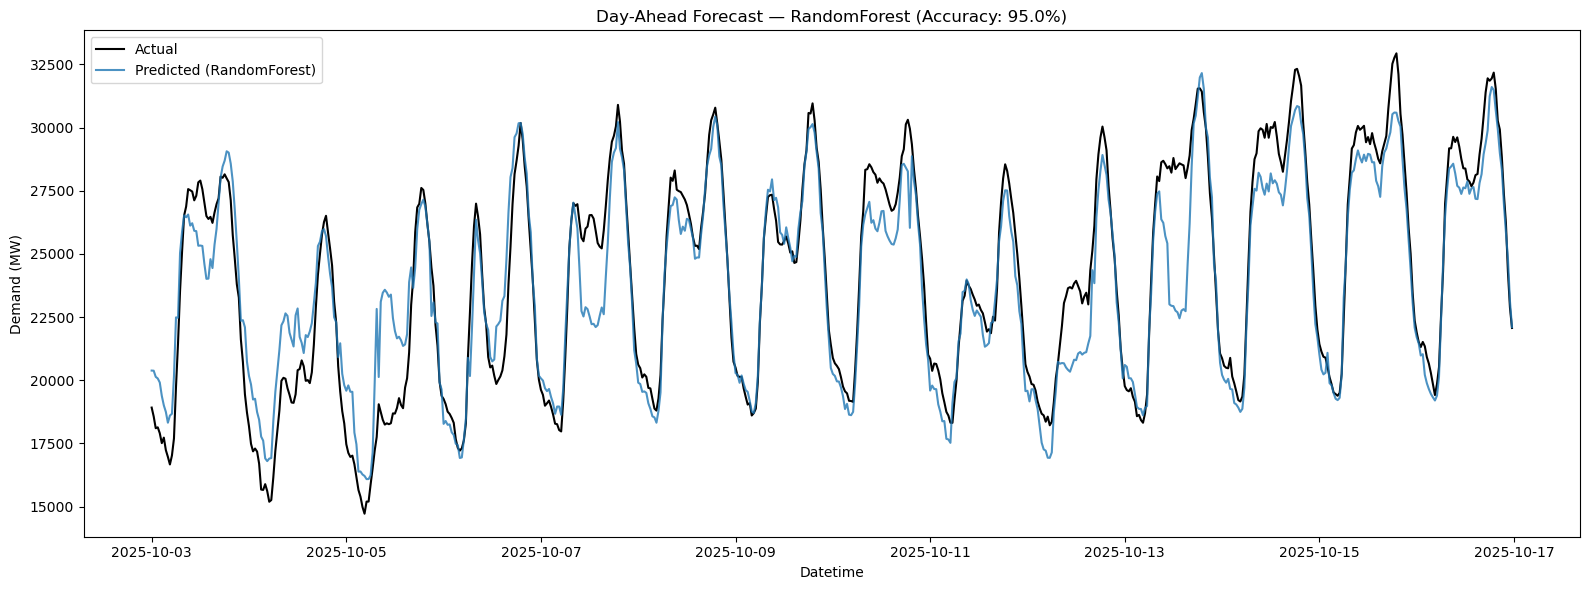

In [8]:
results = pd.DataFrame({
    'Datetime': test['Datetime'].values,
    'Actual': y_test.values,
    'Predicted': pred,
})

sample = results.head(672)  # 2 weeks
plt.figure(figsize=(16, 6))
plt.plot(sample['Datetime'], sample['Actual'], label='Actual', color='black', linewidth=1.5)
plt.plot(sample['Datetime'], sample['Predicted'], label=f'Predicted ({best_model_name})', alpha=0.8)
plt.title(f'Day-Ahead Forecast — {best_model_name} (Accuracy: {accuracy:.1f}%)')
plt.xlabel('Datetime'); plt.ylabel('Demand (MW)')
plt.legend()
plt.tight_layout(); plt.show()

## 3.8 Feature importance (if supported by the model)

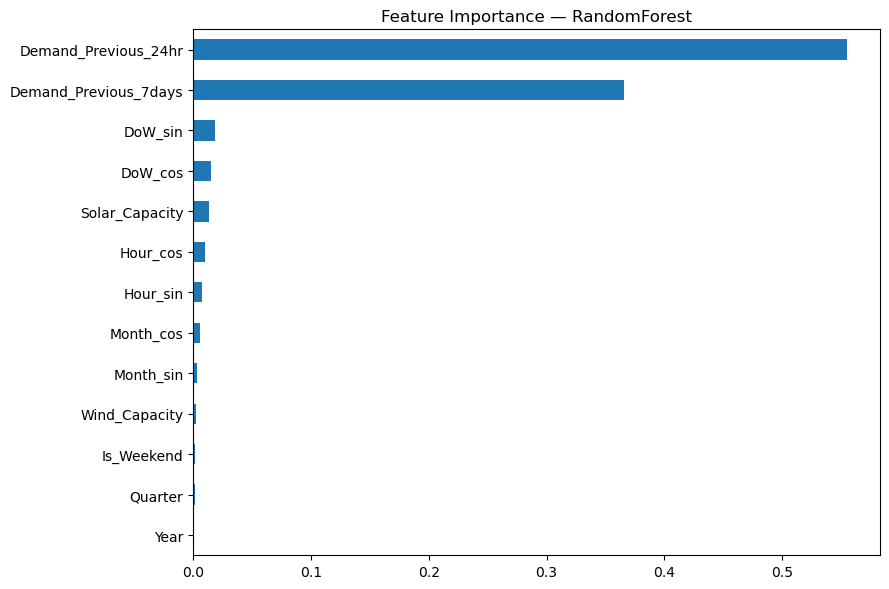

In [9]:
if hasattr(model, 'feature_importances_'):
    importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
    plt.figure(figsize=(9, 6))
    importances.plot(kind='barh')
    plt.title(f'Feature Importance — {best_model_name}')
    plt.tight_layout(); plt.show()
elif hasattr(model, 'coef_'):
    coefs = pd.Series(model.coef_, index=feature_cols).sort_values()
    plt.figure(figsize=(9, 6))
    coefs.plot(kind='barh')
    plt.title(f'Coefficients — {best_model_name}')
    plt.tight_layout(); plt.show()
else:
    print('This model type does not expose feature importances directly.')

In [10]:
import joblib

# Save the trained model
joblib.dump(model, 'elacricty_final_model.pkl')

# Save the feature list too (prediction time same order-il columns venam)
joblib.dump(feature_cols, 'elacricty_feature_cols.pkl')

print("Model saved to outputs/final_model.pkl")

Model saved to outputs/final_model.pkl
